# Tokamak Particle Orbit Explorer — Demo

This notebook demonstrates:
1. Boris pusher energy conservation in a tokamak field.
2. Magnetic moment conservation in a magnetic mirror.
3. Second-order convergence of the Boris algorithm.
4. Banana orbit vs guiding-center approximation.

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from src.particles import Particle
from src.fields import TokamakField, MirrorField
from src.integrators import boris_integrate, guiding_center_integrate
from src.diagnostics import kinetic_energy, magnetic_moment

PROTON_MASS = 1.6726219e-27
PROTON_CHARGE = 1.6021766e-19
E = lambda x, y, z: np.zeros(3)

## Tokamak field

For a large-aspect-ratio circular tokamak:
$$B_\phi = B_0 \frac{R_0}{R}, \quad B_\theta = \frac{r}{R q(r)} B_\phi$$

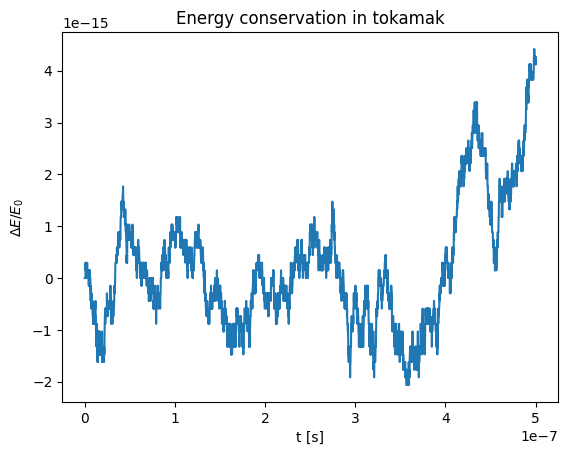

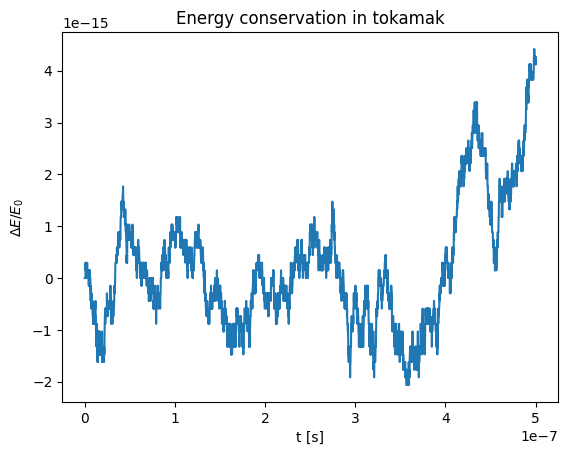

In [2]:
field = TokamakField(B0=5.0, R0=10.0, a=1.0, q0=1.0, q1=2.0)
v = np.array([1e5, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.2, 0.0, 0.0]), v)
result = boris_integrate(field, E, p, dt=1e-10, n_steps=5000)

energies = np.array([kinetic_energy(vv, PROTON_MASS) for vv in result["velocity"]])
fig, ax = plt.subplots()
ax.plot(result["times"], (energies - energies[0]) / energies[0])
ax.set_xlabel("t [s]")
ax.set_ylabel(r"$\Delta E / E_0$")
ax.set_title("Energy conservation in tokamak")
fig

## Magnetic mirror field

On-axis field strength:
$$B_z(z) = B_0 \left(1 + b_m \frac{z^2}{L^2}\right)$$

Off-axis radial field from $\nabla \cdot \mathbf{B} = 0$:
$$B_r(r,z) = -\frac{r}{2} \frac{dB_z}{dz}$$

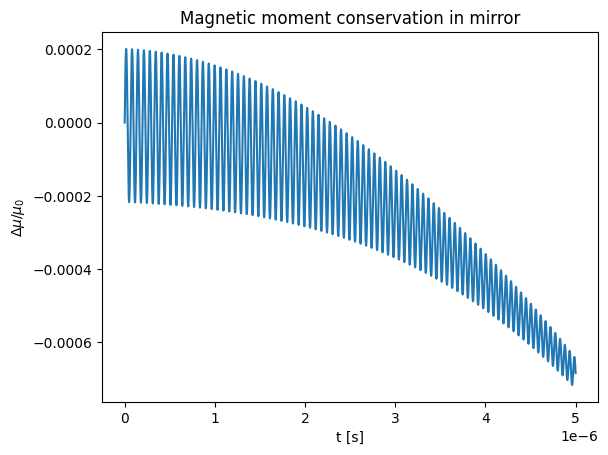

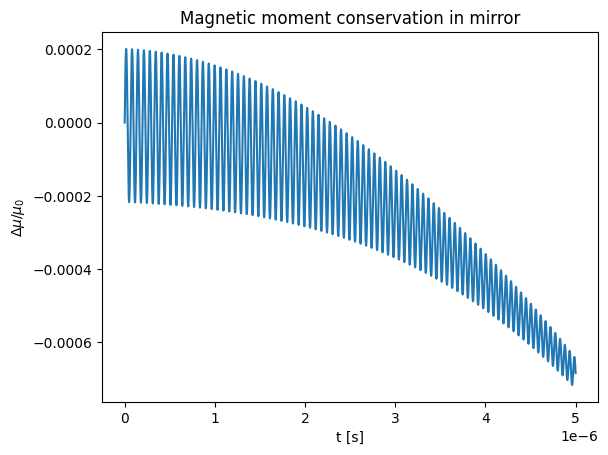

In [3]:
field = MirrorField(B0=1.0, bm=4.0, L=1.0)
v = np.array([1e4, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([0.01, 0.0, 0.0]), v)
result = boris_integrate(field, E, p, dt=1e-9, n_steps=5000)

mus = np.array([magnetic_moment(vv, field, *xx) for vv, xx in zip(result["velocity"], result["trajectory"])])
fig, ax = plt.subplots()
ax.plot(result["times"], (mus - mus[0]) / mus[0])
ax.set_xlabel("t [s]")
ax.set_ylabel(r"$\Delta \mu / \mu_0$")
ax.set_title("Magnetic moment conservation in mirror")
fig

## Boris convergence

The Boris pusher is second-order accurate. We compare the final position at coarser timesteps against a high-resolution reference integration.

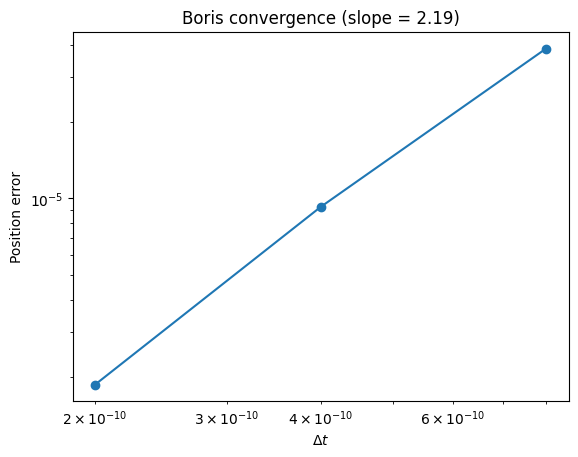

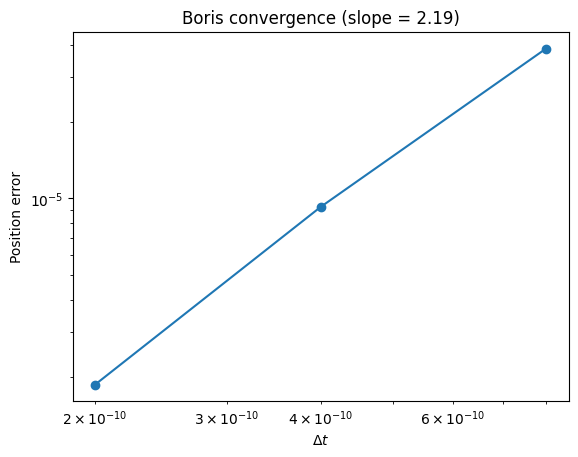

In [4]:
from src.diagnostics import convergence_test

field = MirrorField(B0=1.0, bm=2.0, L=1.0)
v = np.array([1e5, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([0.01, 0.0, 0.0]), v)
dt_list = [2e-10, 4e-10, 8e-10]
result = convergence_test(field, E, p, dt_ref=1e-10, n_steps_ref=8000, dt_list=dt_list)

slope = np.polyfit(np.log(result["dt_list"]), np.log(result["errors"]), 1)[0]
fig, ax = plt.subplots()
ax.loglog(result["dt_list"], result["errors"], "o-")
ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel("Position error")
ax.set_title(f"Boris convergence (slope = {slope:.2f})")
fig

## Banana orbit vs guiding-center

Compare the full Boris orbit with the guiding-center drift approximation in a tokamak.

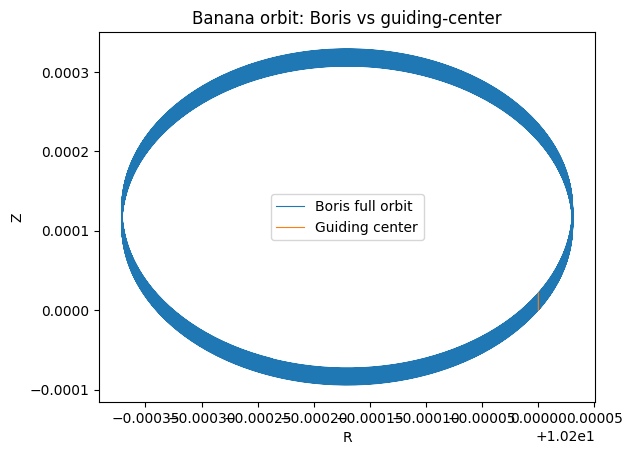

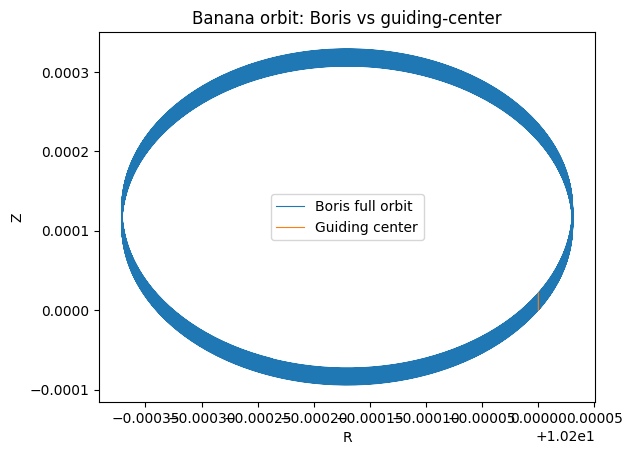

In [5]:
field = TokamakField(B0=5.0, R0=10.0, a=1.0, q0=1.0, q1=2.0)
v = np.array([5e4, 0.0, 8e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.2, 0.0, 0.0]), v)

result_boris = boris_integrate(field, E, p, dt=1e-10, n_steps=8000)
B = field(*p.position)
B_mag = np.linalg.norm(B)
v_para = np.dot(v, B) / B_mag
v_perp_sq = float(v @ v) - v_para ** 2
mu = 0.5 * v_perp_sq / B_mag
result_gc = guiding_center_integrate(field, p, dt=1e-10, n_steps=8000, mu=mu)

R_b = np.sqrt(result_boris["trajectory"][:, 0] ** 2 + result_boris["trajectory"][:, 1] ** 2)
R_g = np.sqrt(result_gc["trajectory"][:, 0] ** 2 + result_gc["trajectory"][:, 1] ** 2)
fig, ax = plt.subplots()
ax.plot(R_b, result_boris["trajectory"][:, 2], label="Boris full orbit", lw=0.8)
ax.plot(R_g, result_gc["trajectory"][:, 2], label="Guiding center", lw=0.8)
ax.set_xlabel("R")
ax.set_ylabel("Z")
ax.set_title("Banana orbit: Boris vs guiding-center")
ax.legend()
fig